# Mini-Project 5: Taxi Route Revenue, Pricing & Fleet Planner

**Scenario.** A matatu association runs 14-seater vehicles on three routes out of Kampala. It wants to forecast demand, understand fares and decide how many vehicles to deploy.

**Data.** Daily passenger counts over 10 days. The Ntinda figures come from the original question. Entebbe and Mukono are **illustrative**. The Extension uses a **simulated**, seeded 60-day series.

All logic is in [`src/taxi.py`](src/taxi.py). Accuracy metrics are shared with Mini-Project 1 through [`src/metrics.py`](src/metrics.py).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.taxi import (
    Backtester,
    ExponentialSmoothingForecaster,
    FleetPlanner,
    LinearTrendForecaster,
    MarketModel,
    MovingAverageForecaster,
    Route,
    SeasonalNaiveForecaster,
    WEEKDAY_FACTORS,
    simulate_weekly_demand,
)

SEED = 11
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. The `Route` class

In [2]:
routes = [
    Route("Kampala-Ntinda", [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], fare=2_000),
    Route("Kampala-Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], fare=5_000),
    Route("Kampala-Mukono", [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], fare=3_000),
]
route_table = pd.DataFrame({
    r.name: {**{f"{k} (passengers)": v for k, v in r.describe().items()},
             "fare (UGX)": r.fare, "mean daily revenue (UGX)": r.daily_revenue().mean(),
             "total 10-day revenue (UGX)": r.total_revenue()}
    for r in routes
}).T
display(route_table)
print(routes[0], "| daily revenue:", routes[0].daily_revenue()[:4], "...")

,mean (passengers),variance (passengers),std (passengers),fare (UGX),mean daily revenue (UGX),total 10-day revenue (UGX)
Kampala-Ntinda,47.40,54.27,7.37,"2,000.00","94,800.00","948,000.00"
Kampala-Entebbe,67.80,45.07,6.71,"5,000.00","339,000.00","3,390,000.00"
Kampala-Mukono,52.00,26.44,5.14,"3,000.00","156,000.00","1,560,000.00"


Route('Kampala-Ntinda', days=10, fare=UGX 2,000) | daily revenue: [ 70000.  80000.  84000. 100000.] ...


Entebbe earns the most (UGX 3.39 m over 10 days) because it combines the highest fare with the highest volume. Ntinda is the most variable relative to its mean (SD 7.4 on a mean of 47.4).

## 2. Supply–demand equilibrium on the Ntinda route

$Q_d = 120 - 0.02P$ and $Q_s = 10 + 0.03P$. Setting both equal to $Q$ gives a linear system in the unknowns $(Q, P)$:

$$\begin{bmatrix}1 & 0.02\\ 1 & -0.03\end{bmatrix}\begin{bmatrix}Q\\P\end{bmatrix} = \begin{bmatrix}120\\10\end{bmatrix}$$

In [3]:
market = MarketModel(demand_intercept=120, demand_slope=0.02, supply_intercept=10, supply_slope=0.03)
A, rhs = market.as_linear_system()
q_star, p_star = market.equilibrium()
print("A =", A.tolist(), " b =", rhs.tolist())
print(f"Equilibrium: P* = UGX {p_star:,.0f}, Q* = {q_star:.0f} passengers per trip-hour")
print(f"Hand check: 120 - 0.02P = 10 + 0.03P  =>  P = 110/0.05 = {110 / 0.05:,.0f}")
current = 2_000
print(f"At UGX {current:,}: Qd = {market.quantity_demanded(current):.0f}, Qs = {market.quantity_supplied(current):.0f}, "
      f"excess demand = {market.excess_demand(current):.0f} passengers per trip-hour")

A = [[1.0, 0.02], [1.0, -0.03]]  b = [120, 10]
Equilibrium: P* = UGX 2,200, Q* = 76 passengers per trip-hour
Hand check: 120 - 0.02P = 10 + 0.03P  =>  P = 110/0.05 = 2,200
At UGX 2,000: Qd = 80, Qs = 70, excess demand = 10 passengers per trip-hour


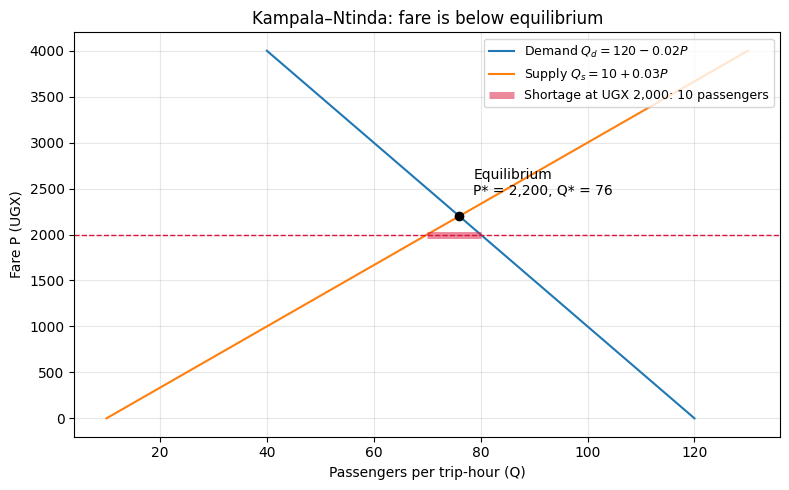

In [4]:
prices = np.linspace(0, 4000, 200)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot([market.quantity_demanded(p) for p in prices], prices, label="Demand $Q_d = 120 - 0.02P$")
ax.plot([market.quantity_supplied(p) for p in prices], prices, label="Supply $Q_s = 10 + 0.03P$")
ax.plot(q_star, p_star, "ko")
ax.annotate(f"Equilibrium\nP* = {p_star:,.0f}, Q* = {q_star:.0f}", (q_star, p_star), xytext=(10, 15), textcoords="offset points")
ax.axhline(current, color="crimson", ls="--", lw=1)
ax.hlines(current, market.quantity_supplied(current), market.quantity_demanded(current), color="crimson", lw=5, alpha=0.5,
          label=f"Shortage at UGX {current:,}: {market.excess_demand(current):.0f} passengers")
ax.set_xlabel("Passengers per trip-hour (Q)")
ax.set_ylabel("Fare P (UGX)")
ax.set_title("Kampala–Ntinda: fare is below equilibrium")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Interpretation.** The equilibrium fare is **UGX 2,200**, at which 76 passengers per trip-hour want to travel and 76 seats are offered. The current UGX 2,000 is **UGX 200 below equilibrium**. At that fare, 80 people want to travel but operators only supply 70 seats, so there is a **shortage of 10 passengers per trip-hour**. That matches what commuters experience on the route at peak times: queues at the stage and overloading.

Raising the fare to 2,200 would clear the market. Demand would fall by 4 and supply rise by 6, and drivers would earn more per trip. The association should weigh that against affordability: Ntinda riders are price-sensitive commuters. The fare may also be held down by custom or by regulation. An alternative that keeps the fare at UGX 2,000 is to add *supply*: more vehicles at peak hours shift the supply curve to the right.

## 3. Forecasters

`SeriesForecaster` is an abstract base class with `fit(series)` and `predict(horizon)`. The subclasses are:

| Class | Forecast for tomorrow |
|---|---|
| `MovingAverageForecaster(3)` | mean of the last 3 days (the original method) |
| `ExponentialSmoothingForecaster(α)` | smoothed level $\ell_t = \alpha y_t + (1-\alpha)\ell_{t-1}$ |
| `LinearTrendForecaster` | least-squares line through all days so far, extended one day |
| `SeasonalNaiveForecaster(7)` | same weekday last week (used in the Extension) |

## 4. Walk-forward backtesting over days 4–10 and α grid search

For each target day $t \in \{4, \dots, 10\}$ every model is fitted only on days $1, \dots, t-1$ and forecasts day $t$, so no future information is ever used. The SES α is tuned by grid search over 0.05–1.00 (step 0.05) on the same backtest.

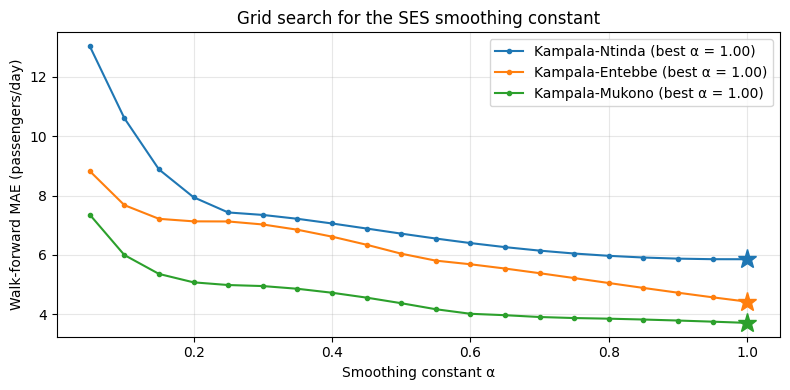

Best alpha per route: {'Kampala-Ntinda': 1.0, 'Kampala-Entebbe': 1.0, 'Kampala-Mukono': 1.0}


In [5]:
backtester = Backtester(start_index=3)  # 0-based index 3 = day 4
alphas = np.round(np.arange(0.05, 1.0001, 0.05), 2)
best_alpha, alpha_scores = {}, {}
for r in routes:
    best_alpha[r.name], alpha_scores[r.name] = backtester.tune_alpha(r.passengers, alphas)
alpha_df = pd.DataFrame(alpha_scores)
fig, ax = plt.subplots(figsize=(8, 4))
for i, (name, scores) in enumerate(alpha_scores.items()):
    ax.plot(list(scores), list(scores.values()), "-o", ms=3, color=f"C{i}", label=f"{name} (best α = {best_alpha[name]:.2f})")
    ax.plot(best_alpha[name], scores[best_alpha[name]], "*", ms=14, color=f"C{i}")
ax.set_xlabel("Smoothing constant α")
ax.set_ylabel("Walk-forward MAE (passengers/day)")
ax.set_title("Grid search for the SES smoothing constant")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()
print("Best alpha per route:", best_alpha)

In [6]:
MODEL_FACTORIES = {
    "3-day moving average": lambda r: MovingAverageForecaster(3),
    "SES (tuned α)": lambda r: ExponentialSmoothingForecaster(best_alpha[r.name]),
    "Linear trend": lambda r: LinearTrendForecaster(),
}
results = {r.name: {label: backtester.run(r.passengers, make(r)) for label, make in MODEL_FACTORIES.items()} for r in routes}
mae_table = pd.DataFrame({route: {label: res.mae for label, res in models.items()} for route, models in results.items()})
best_model = mae_table.idxmin()
print("Walk-forward MAE (passengers/day), days 4–10:")
display(mae_table)
print("Best model per route:", best_model.to_dict())

Walk-forward MAE (passengers/day), days 4–10:


,Kampala-Ntinda,Kampala-Entebbe,Kampala-Mukono
3-day moving average,7.52,7.19,5.33
SES (tuned α),5.86,4.43,3.71
Linear trend,7.87,7.71,6.39


Best model per route: {'Kampala-Ntinda': 'SES (tuned α)', 'Kampala-Entebbe': 'SES (tuned α)', 'Kampala-Mukono': 'SES (tuned α)'}


**Interpretation.**
* The grid search picks **α = 1.0 on every route**, the edge of the grid. With α = 1, SES puts all its weight on the latest observation and becomes the *naive* forecast "tomorrow = today". That it wins says demand on these routes is **persistent**: a busy day tends to be followed by another busy day, so averaging in older days (moving average, small α) only adds lag.
* Tuned SES beats the 3-day moving average by 22–38% in MAE. The moving average responds to a turning point (the peak on day 6) more slowly.
* The **linear trend is the worst model on every route**. Demand rose until day 6 and then fell back, so a line fitted to the early rise keeps over-forecasting.
* Caveat: α was tuned on the *same* seven days it is scored on. Its MAE is therefore optimistic, and with only seven forecast errors per route the ranking is not statistically robust. A proper test would tune α on one window and score on a later one.

In [7]:
# Day-by-day one-step errors (passengers) behind the MAE table, Ntinda route
pd.DataFrame({label: res.actual - res.predicted for label, res in results["Kampala-Ntinda"].items()},
             index=[f"day {t + 1}" for t in results["Kampala-Ntinda"]["Linear trend"].target_index]).round(1)

,3-day moving average,SES (tuned α),Linear trend
day 4,11.00,8.00,4.00
day 5,11.00,5.00,1.50
day 6,11.00,5.00,0.60
day 7,-7.00,-12.00,-16.80
day 8,-2.30,4.00,-8.30
day 9,-6.30,-5.00,-12.40
day 10,-4.00,-2.00,-11.50


## 5. Forecast day 11 revenue with the best model

In [8]:
day11 = {}
for r in routes:
    chosen = best_model[r.name]
    pax = MODEL_FACTORIES[chosen](r).fit(r.passengers).predict(1)[0]
    day11[r.name] = {"model": chosen, "passengers": pax, "revenue (UGX)": pax * r.fare}
day11_df = pd.DataFrame(day11).T
day11_df

,model,passengers,revenue (UGX)
Kampala-Ntinda,SES (tuned α),45.00,"90,000.00"
Kampala-Entebbe,SES (tuned α),64.00,"320,000.00"
Kampala-Mukono,SES (tuned α),50.00,"150,000.00"


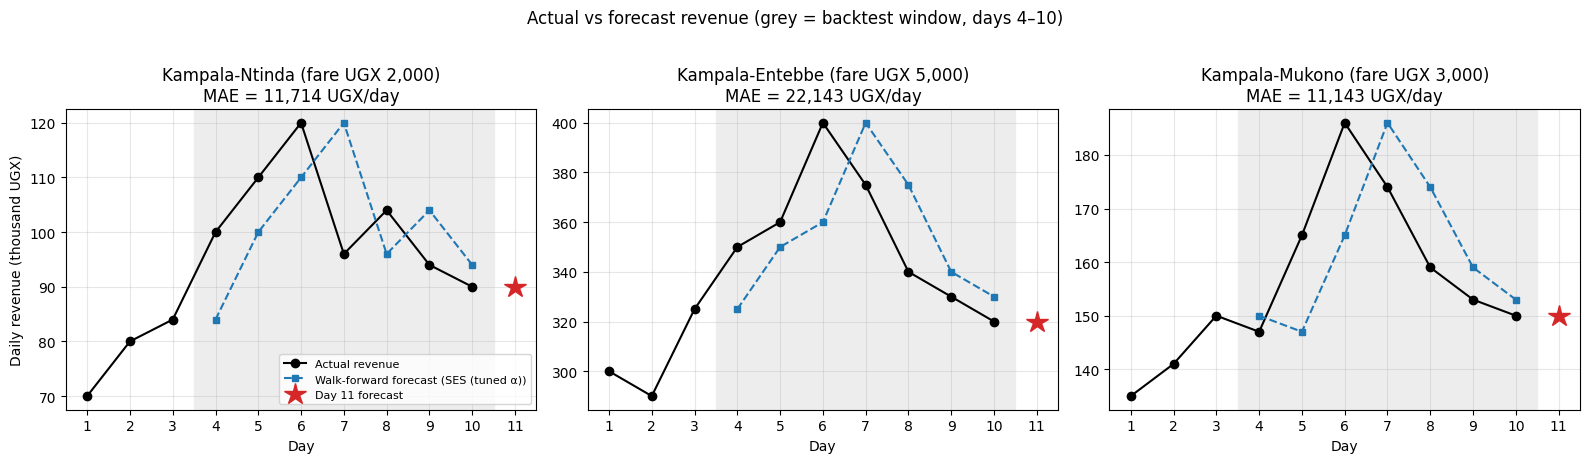

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
days = np.arange(1, 11)
for ax, r in zip(axes, routes):
    chosen = best_model[r.name]
    res = results[r.name][chosen]
    ax.plot(days, r.daily_revenue() / 1000, "k-o", label="Actual revenue")
    ax.plot(res.target_index + 1, res.predicted * r.fare / 1000, "C0--s", ms=5, label=f"Walk-forward forecast ({chosen})")
    ax.plot(11, day11[r.name]["revenue (UGX)"] / 1000, "C3*", ms=16, label="Day 11 forecast")
    ax.axvspan(3.5, 10.5, color="0.93", zorder=0)
    ax.set_title(f"{r.name} (fare UGX {r.fare:,.0f})\nMAE = {res.mae * r.fare:,.0f} UGX/day")
    ax.set_xlabel("Day")
    ax.set_xticks(range(1, 12))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Daily revenue (thousand UGX)")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Actual vs forecast revenue (grey = backtest window, days 4–10)", y=1.02)
fig.tight_layout()
plt.show()

## 6. Fleet planning for day 11

Each vehicle makes 8 one-way trips a day with 14 seats, so it can carry **112 passengers per day**. I add a 15% buffer to the forecast and **round up**: a fractional vehicle cannot be deployed, and rounding down would leave passengers stranded.

In [10]:
planner = FleetPlanner(trips_per_vehicle=8, seats=14, buffer=0.15)
fleet = pd.DataFrame({
    r.name: {"forecast passengers": day11[r.name]["passengers"],
             "with 15% buffer": day11[r.name]["passengers"] * 1.15,
             "vehicle-days needed (exact)": day11[r.name]["passengers"] * 1.15 / planner.daily_capacity,
             "vehicles to deploy": planner.vehicles_needed(day11[r.name]["passengers"]),
             "expected load factor": f"{planner.load_factor(day11[r.name]['passengers']):.0%}"}
    for r in routes
}).T
fleet

,forecast passengers,with 15% buffer,vehicle-days needed (exact),vehicles to deploy,expected load factor
Kampala-Ntinda,45.00,51.75,0.46,1,40%
Kampala-Entebbe,64.00,73.60,0.66,1,57%
Kampala-Mukono,50.00,57.50,0.51,1,45%


**Interpretation.** Every route needs **one vehicle** on day 11, even after the buffer. The exact requirement is 0.46–0.66 of a vehicle. Taken literally, one matatu running 8 trips would be only 40–57% full on average, which an association would see as under-utilisation. There are two sensible readings:

1. **The counts are genuinely daily.** Then a single vehicle covers each route, and the association could free up vehicles for busier routes, or run fewer trips at off-peak times to save fuel.
2. **The counts are per peak period or per stage**, which is closer to how busy these routes really are. Then the same `FleetPlanner` scales linearly: for example, if the figures were per hour across a 10-hour operating day, Entebbe would carry about 640 passengers and need ⌈640 × 1.15 / 112⌉ = 7 vehicles.

The planner returns 0 for zero demand and never less than 1 when there is any demand.

## Extension: 60 days with a weekly pattern, seasonal-naive vs moving average

I simulate 60 days that start on a Monday. The base demand is 50 passengers with the weekday multipliers below (busiest on Friday, quietest on Sunday) and Gaussian noise (SD 3). All models are backtested walk-forward from day 15 to day 60. Every model then has at least two weeks of history, so the comparison is fair.

In [11]:
print("Weekday multipliers:", WEEKDAY_FACTORS)
sim = simulate_weekly_demand(60, base=50, rng=np.random.default_rng(SEED), noise_sd=3)
bt60 = Backtester(start_index=14)
sim_alpha, _ = bt60.tune_alpha(sim, alphas)
ext_models = [SeasonalNaiveForecaster(7), MovingAverageForecaster(3), ExponentialSmoothingForecaster(sim_alpha), LinearTrendForecaster()]
ext_results = {m.name: bt60.run(sim, m) for m in ext_models}
ext_table = pd.Series({k: v.mae for k, v in ext_results.items()}, name="walk-forward MAE (passengers/day)").sort_values()
display(ext_table.to_frame())
sn, ma = ext_results["Seasonal naive (period=7)"].mae, ext_results["3-day moving average"].mae
print(f"Seasonal naive reduces MAE by {(1 - sn / ma):.0%} relative to the 3-day moving average.")

Weekday multipliers: {'Mon': 1.0, 'Tue': 0.95, 'Wed': 0.95, 'Thu': 1.0, 'Fri': 1.35, 'Sat': 1.1, 'Sun': 0.6}


,walk-forward MAE (passengers/day)
Seasonal naive (period=7),3.04
SES (alpha=0.05),7.00
Linear trend,7.40
3-day moving average,8.21


Seasonal naive reduces MAE by 63% relative to the 3-day moving average.


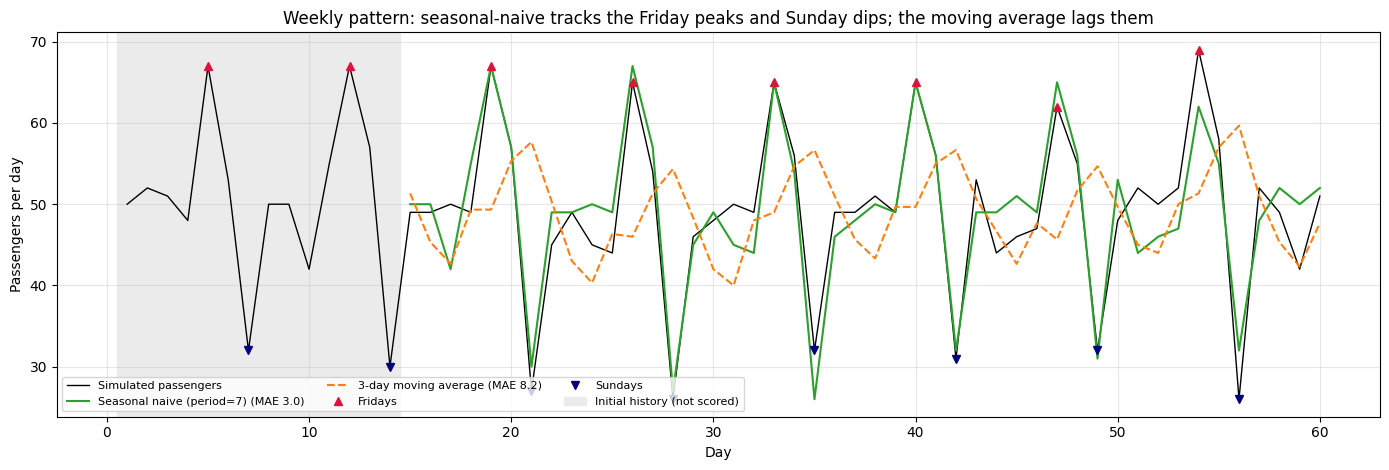

In [12]:
fig, ax = plt.subplots(figsize=(14, 4.8))
d = np.arange(1, 61)
ax.plot(d, sim, "k-", lw=1, label="Simulated passengers")
for name, style in [("Seasonal naive (period=7)", "C2-"), ("3-day moving average", "C1--")]:
    res = ext_results[name]
    ax.plot(res.target_index + 1, res.predicted, style, lw=1.5, label=f"{name} (MAE {res.mae:.1f})")
fridays = d[(d - 1) % 7 == 4]
sundays = d[(d - 1) % 7 == 6]
ax.plot(fridays, sim[fridays - 1], "^", color="crimson", label="Fridays")
ax.plot(sundays, sim[sundays - 1], "v", color="navy", label="Sundays")
ax.axvspan(0.5, 14.5, color="0.92", zorder=0, label="Initial history (not scored)")
ax.set_xlabel("Day")
ax.set_ylabel("Passengers per day")
ax.set_title("Weekly pattern: seasonal-naive tracks the Friday peaks and Sunday dips; the moving average lags them")
ax.legend(ncol=3, fontsize=8, loc="lower left")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Why seasonal-naive wins.** With a strong weekly cycle, the best single predictor of next Friday is *last Friday*. The 3-day moving average averages Tuesday–Thursday to forecast Friday, so it under-forecasts every Friday peak by roughly 25–30%. Then it carries the peak into the following days and over-forecasts Sunday. Its errors are systematic, not random. Seasonal-naive errors come only from noise: the difference between two noisy observations a week apart has SD $3\sqrt2 \approx 4.2$, so the expected MAE is $4.2\sqrt{2/\pi} \approx 3.4$, close to the observed 3.0. Even the best-tuned SES (α = 0.05, essentially a long-run average) cannot compete, because it ignores the weekday. A natural next step would combine the two ideas: a seasonal level smoothed over several weeks, as in Holt-Winters.

## Findings & Limitations

**Findings.** Entebbe is the association's most valuable route. It brings in UGX 339k a day, more than Ntinda and Mukono combined (UGX 251k), because it has both the highest fare and the most passengers. On Ntinda the UGX 2,000 fare is UGX 200 below the market-clearing UGX 2,200, which leaves a shortage of 10 passengers per trip-hour. The association therefore has room either to raise the fare modestly or, better for commuters, to add peak-hour vehicles. In forecasting, the simplest adaptive model won: tuned SES chose α = 1 ("tomorrow equals today") and beat the original 3-day moving average by 22–38% in MAE. The linear trend was worst everywhere, because it extrapolated a short rise that had already reversed. Forecast day-11 revenue is about UGX 90k (Ntinda), 320k (Entebbe) and 150k (Mukono). Each route needs only one vehicle, running at 40–57% load. That points either to over-capacity or to counts that are per period rather than per day, and the association should confirm which before acting on it. The 60-day extension makes the practical point that once a weekly cycle exists, a seasonal-naive forecast cuts error by 63% compared with the moving average. The forecasting method should follow the structure of the data.

**Limitations.** Ten days is far too short to tune α, choose a model and detect weekly seasonality at the same time. Because α was tuned and scored on the same window, its advantage is overstated. The supply and demand curves are given, not estimated from data, and they assume a linear response to price. The fleet model ignores traffic congestion, which changes how many trips a vehicle can make, and stage-by-stage boarding (passengers alighting and boarding along the route), which raises real capacity. The weekly multipliers in the simulation are my own assumptions.